<a href="https://colab.research.google.com/github/gligormilicevic/ml-sentiment-analysis-project/blob/main/notebook/product_reviews_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Loading and inspecting the dataset

Before diving into analysis, we first need to load the dataset and take a look at its structure.

In this step, we will:
- load the CSV file from GitHub,
- check how many rows and columns we have,
- display the first few rows, and finally,
- review data types and basic metadata for each column.

This will help us ensure the dataset is correctly loaded and ready for further exploration.

In [1]:
import pandas as pd

# load dataset from GitHub
url = "https://raw.githubusercontent.com/gligormilicevic/ml-sentiment-analysis-project/main/data/product_reviews_full.csv"
df = pd.read_csv(url)

# print("Number of rows:", len(df))
# print("First 5 rows:")
# print(df.head())

# Print shape (number of rows and columns)
print("Dataset shape (rows, columns):", df.shape)

# Show first 5 rows
print("\nFirst 5 rows:")
display(df.head())

# Show column data types and non-null counts
print("\nDataset info:")
df.info()

Dataset shape (rows, columns): (171380, 6)

First 5 rows:


,review_uuid,product_name,product_price,review_title,review_text,sentiment
0,31b07b9a-4567-4db1-81f6-1bcef33b3e7b,Candes 12 L Room/Personal Air Cooler??????(Whi...,48.18,Super!,great cooler excellent air flow and for this p...,positive
1,1cb2b4b5-9805-4c2d-9393-6b1382cb7c53,Candes 12 L Room/Personal Air Cooler??????(Whi...,48.18,Awesome,best budget 2 fit cooler nice cooling,positive
2,f64165f0-29a2-4cfb-8b15-13c0c893e54d,Candes 12 L Room/Personal Air Cooler??????(Whi...,48.18,Fair,the quality is good but the power of air is de...,positive
3,e442e083-a343-4052-b015-41e531e52d3e,Candes 12 L Room/Personal Air Cooler??????(Whi...,48.18,Useless product,very bad product its a only a fan,negative
4,f4abefb8-22f0-4672-af73-2aa2954b24e0,Candes 12 L Room/Personal Air Cooler??????(Whi...,48.18,Fair,ok ok product,Neutral



Dataset info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 171380 entries, 0 to 171379
Data columns (total 6 columns):
 #   Column         Non-Null Count   Dtype 
---  ------         --------------   ----- 
 0   review_uuid    171380 non-null  object
 1   product_name   171380 non-null  object
 2   product_price  170954 non-null  object
 3   review_title   171379 non-null  object
 4   review_text    171379 non-null  object
 5   sentiment      166369 non-null  object
dtypes: object(6)
memory usage: 7.8+ MB


## Checking for missing values

Missing data can cause problems during model training or analysis. Here, we will:
- count the number of missing (NaN) values per column, and
- visualize missing values using a heatmap.

This will help us identify any columns that require cleaning or imputation.

In [2]:
# Count missing values per column
print("Missing values per column:")
print(df.isna().sum())

Missing values per column:
review_uuid         0
product_name        0
product_price     426
review_title        1
review_text         1
sentiment        5011
dtype: int64


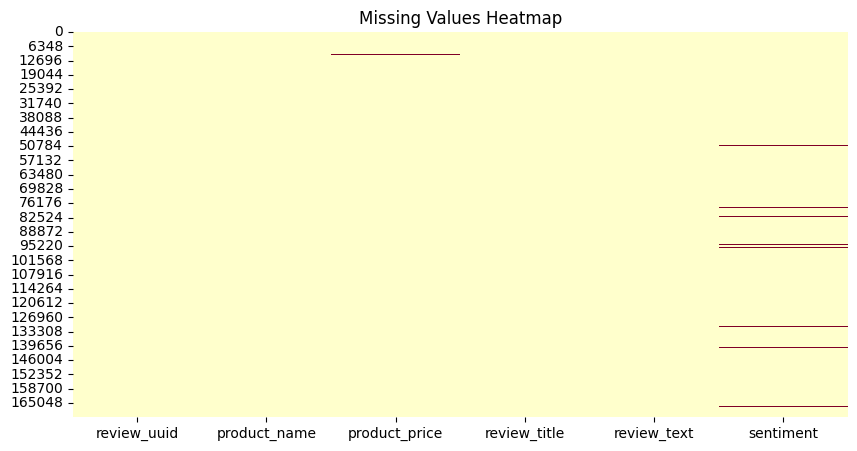

In [3]:
# Visualize missing data with seaborn heatmap
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
sns.heatmap(df.isna(), cbar=False, cmap="YlOrRd")
plt.title("Missing Values Heatmap")
plt.show()

## Sentiment analysis

Let's check how many reviews are labeled as positive vs. negative vs. neutral.

This helps us:
- understand the balance between classes, and
- detect if the dataset is skewed.

In [4]:
# Count occurrences of each sentiment label
sentiment_counts = df['sentiment'].value_counts()

# Print counts
print("Sentiment distribution (counts):")
print(sentiment_counts)

Sentiment distribution (counts):
sentiment
positive    85537
negative    32369
Positive    22361
Negative    12392
neutral     10508
Neutral      3202
Name: count, dtype: int64


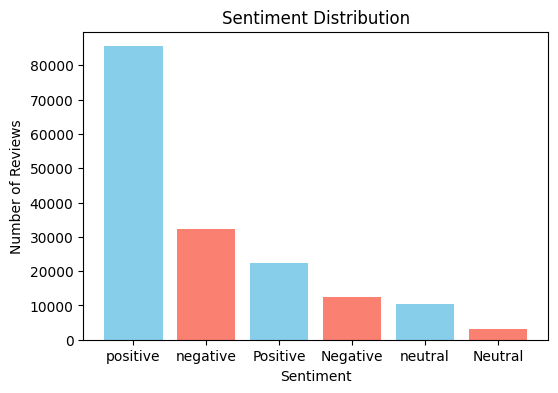

In [5]:
# Plot sentiment distribution
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 4))
plt.bar(sentiment_counts.index, sentiment_counts.values, color=['skyblue', 'salmon'])
plt.title("Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.show()

## Exploring the product price column

Before we can use price data in any meaningful way, we need to understand how it is stored and formatted. In this section, we will:
- check the data type of the `product_price` column,
- preview a few sample values,
- identify the most common price entries, and
- detect non-numeric or problematic values such as "Free", "N/A", or corrupted symbols.

This is an important part of data cleaning. Even if a value looks like a number (e.g., `$48.19`), it may still be stored as a string and cause problems during numeric analyses or modeling.

Let's investigate what we're working with!

In [6]:
# 1. Check the data type of the 'product_price' column
print("Data type of product_price column:", df['product_price'].dtype)

# 2. Display the first 10 values from the column
print("\nFirst 10 values in product_price column:")
print(df['product_price'].head(10))

# 3. Show the 20 most frequent values in the column
print("\nTop 20 most frequent values in product_price column:")
print(df['product_price'].value_counts().head(20))

# 4. Check for known non-numeric text values
problematic_values = ['Free', 'Not Available', 'N/A', 'None', '-', 'free', 'unknown', 'Unavailable']
# Identify rows containing these specific non-numeric values
mask_problematic = df['product_price'].astype(str).str.strip().isin(problematic_values)
df_problematic = df[mask_problematic]
print(f"\nFound {len(df_problematic)} rows with problematic textual values:")
display(df_problematic[['product_price']].drop_duplicates())

# 5. Find and display some of the non-numeric values
price_clean = df['product_price'].astype(str).str.strip()
price_numeric = pd.to_numeric(price_clean, errors='coerce')

invalid_prices = df[price_numeric.isna()]
print("Number of non-numeric prices:", len(invalid_prices))
display(invalid_prices[['product_price']].drop_duplicates().head(20))

Data type of product_price column: object

First 10 values in product_price column:
0    48.18
1    48.18
2    48.18
3    48.18
4    48.18
5    48.18
6    48.18
7    48.18
8    48.18
9    48.18
Name: product_price, dtype: object

Top 20 most frequent values in product_price column:
product_price
2.63        4483
5.41        2648
$5.41       2577
19.27       2575
$2.63       2499
42.16       2242
168.66      2175
8.42        2103
6.01        1857
373.48      1824
3.6         1778
18.06       1710
$19.27      1671
$3.60       1608
96.37       1496
$168.66     1461
3.0         1395
$6.01       1359
3.24        1333
2.4         1321
Name: count, dtype: int64

Found 0 rows with problematic textual values:


,product_price


Number of non-numeric prices: 68858


,product_price
22,NaN
34279,$6.86
34512,$2.76
34553,$6.95
35245,$4.35
36212,$19.27
36613,$21.67
36622,$7.22
36753,$9.63
36766,$7.82


## Removing missing values

We already analyzed missing data in the previous step.
Now we will simply drop all rows that contain missing values,
and check the new shape and count missing val

In [7]:
# Drop all rows with missing values
df = df.dropna()

# Display new shape of the dataset
print("New dataset shape:", df.shape)

# Count missing values per column
print("Missing values per column:")
print(df.isna().sum())


New dataset shape: (165960, 6)
Missing values per column:
review_uuid      0
product_name     0
product_price    0
review_title     0
review_text      0
sentiment        0
dtype: int64


### Mini-activity: How much data did we lose?

Before permanently deleting rows with missing values, calculate:
- How many total rows does the dataset have before removal?
- How many rows are there after `dropna()`?
- What is the percentage of lost data?
- Bonus: Look at a random sample of rows that will be removed. Is there anything interesting among them? Do you want to keep or fill any of those values?

Think about:
- Is the dataset still large enough for analysis?
- Is deletion the simplest and smartest option for our case?

In [8]:
import pandas as pd


# load dataset from GitHub
url = "https://raw.githubusercontent.com/vladimir-dresevic/ml-product-reviews-project/main/data/product_reviews_full.csv"


df = pd.read_csv(url)

# Count the number of rows before removing missing values
rows_before = len(df)

# Filter out rows that contain at least one missing value
rows_with_nan = df[df.isnull().any(axis=1)]

# Display a random sample of rows that will be removed
print(" Randomly selected rows containing missing values:\n")
print(rows_with_nan.sample(n=min(5, len(rows_with_nan)), random_state=42))

# Remove rows with any missing values
df_cleaned = df.dropna()

# Count the number of rows after removing missing values
rows_after = len(df_cleaned)

# Show removal statistics
print("\n Removal statistics:")
print(f"- Number of rows before: {rows_before}")
print(f"- Number of rows after: {rows_after}")
print(f"- Number of removed rows: {rows_before - rows_after}")


 Randomly selected rows containing missing values:

                                 review_uuid  \
138622  be155fca-c19b-4ca5-8a11-dcda5f334e18   
48332   0fcacd59-eb69-4c73-adb7-8bdd6c86cdbd   
10021   772ca541-7296-4065-b969-2eaef308623a   
9637    05b646fc-66a0-4d3b-a97a-ccb6b367eaa2   
156343  3a97cd00-5eea-4533-889c-c3ed7eedda36   

                                             product_name product_price  \
138622  SAMSUNG 253 L Frost Free Double Door 3 Star Re...      $295.06    
48332   Men Solid Single Breasted Casual Blazer??????(...       $38.54    
10021   CEAT Hitman Full Size Double Blade Poplar Cric...          3.96   
9637    Hindware Ripple 90 Auto Clean Wall Mounted Chi...        172.28   
156343  APPLE iPad (9th Gen) 64 GB ROM 10.2 inch with ...      $361.33    

                  review_title                            review_text  \
138622               Very Good  good design and effective performance   
48332                      Nan                                

## Parsing the 'product_price' column

We noticed that some product prices are stored as numbers, while others contain a currency prefix like `$` (e.g., `$48.18` or `$131.90`).

To make this column usable, we will:
- remove the `$` symbol and any extra characters,
- convert all values to numbers (`float`), and
- drop invalid rows if conversion fails.

In [9]:
# Step 1: Convert to string and remove the 'USD' prefix and any leading/trailing spaces
df['product_price_cleaned'] = (
    df['product_price']
    .astype(str)
    .str.replace(r'$', '', regex=True)    # Remove '$'
    .str.replace(r'[^\d.]', '', regex=True) # Remove all non-numeric characters except the dot
    .str.strip()
)

# Step 2: Convert cleaned string to float
df['product_price'] = pd.to_numeric(df['product_price_cleaned'], errors='coerce')

# Step 3: Drop the temporary column
df = df.drop(columns=['product_price_cleaned'])

# Step 4: Drop any rows where conversion failed (still NaN)
df = df.dropna(subset=['product_price'])

# Step 5: Confirm result
print("Column type after parsing:", df['product_price'].dtype)
print("\nPrice summary:")
print(df['product_price'].describe())

Column type after parsing: float64

Price summary:
count    170954.000000
mean         65.709872
std         135.789769
min           0.180000
25%           4.190000
50%          14.450000
75%          66.250000
max        1566.140000
Name: product_price, dtype: float64


## Standardizing the sentiment column

The `sentiment` column should only contain `"positive"`, `"negative"`, and `"neutral"` values.

We will:
- convert all values to lowercase,
- convert the column type to `category`, and
- check the results.

In [10]:
# Step 1: Convert all sentiment values to lowercase and strip extra spaces
df['sentiment'] = df['sentiment'].astype(str).str.lower().str.strip()

# Step 2: Show all unique values in the sentiment column
print("Unique sentiment values after cleaning:")
print(df['sentiment'].value_counts())

# Step 3: Convert column type to 'category'
df['sentiment'] = df['sentiment'].astype('category')
print("\nSentiment column converted to type:", df['sentiment'].dtype)

Unique sentiment values after cleaning:
sentiment
positive    107619
negative     44663
neutral      13678
nan           4994
Name: count, dtype: int64

Sentiment column converted to type: category


## Removing irrelevant columns

We will now remove columns that are not useful for model training:
- `review_uuid` – just a unique ID,
- `product_name` – too specific and inconsistent.

The key features we want to keep are:
- `review_title` – short description of the whole review,
- `review_text` – the main input for sentiment prediction,
- `product_price` – to be analyzed further,
- `sentiment` – the target variable.

In [11]:
# Drop columns that are not useful for modeling
df = df.drop(columns=['review_uuid', 'product_name'])

# Preview remaining columns
print("Remaining columns:")
print(df.columns.tolist())

Remaining columns:
['product_price', 'review_title', 'review_text', 'sentiment']


## Does product price affect sentiment?

Let's explore whether the price of a product has any influence on the sentiment of reviews.

We will:
- look at summary statistics of product prices per sentiment, and
- visualize the price distribution grouped by sentiment.

Price summary by sentiment:
              count       mean         std   min     25%    50%     75%  \
sentiment                                                                 
nan          4994.0  63.150212  130.542273  0.71  4.1925  14.08  60.230   
negative    44663.0  59.655028  112.306009  0.71  4.3500  18.06  60.710   
neutral     13678.0  55.532342  107.524238  0.71  3.3000  10.23  59.845   
positive   107619.0  69.635003  147.485845  0.18  4.2000  14.08  66.250   

               max  
sentiment           
nan        1048.07  
negative   1566.14  
neutral    1204.70  
positive   1048.07  


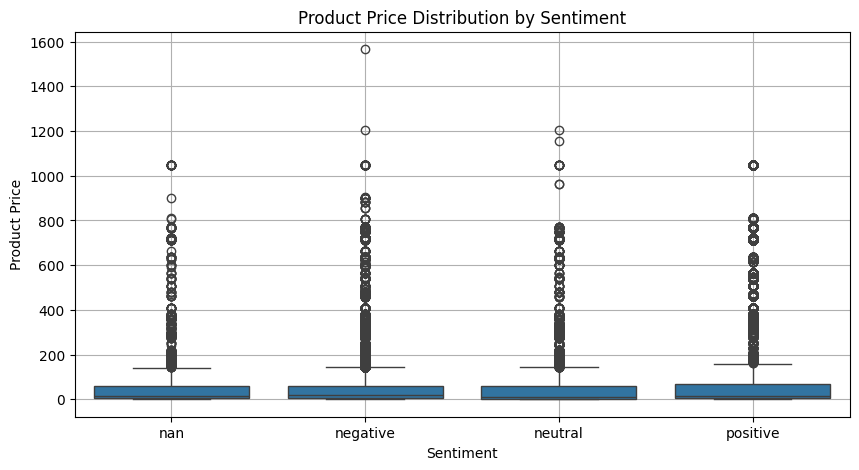

In [12]:
import seaborn as sns
import matplotlib.pyplot as plt

# Show summary statistics grouped by sentiment
print("Price summary by sentiment:")
print(df.groupby('sentiment', observed=False)['product_price'].describe())

# Boxplot of prices by sentiment
plt.figure(figsize=(10, 5))
sns.boxplot(data=df, x='sentiment', y='product_price')
plt.title("Product Price Distribution by Sentiment")
plt.xlabel("Sentiment")
plt.ylabel("Product Price")
plt.grid(True)
plt.show()

### Mini-challenge: Advanced feature engineering and deeper visualization

To dive deeper into how review length affects sentiment, let's expand our analysis:
- calculate the **word count** instead of just the character count,
- create a **violin plot** to examine the distribution density of word counts per sentiment, and
- plot overlapping histograms to compare positive, negative, and neutral reviews side-by-side.

Statistika broja reči po sentimentu:
              count       mean        std  min  25%  50%   75%    max
sentiment                                                            
nan          4994.0   9.087705  14.299279  1.0  2.0  4.0  10.0   99.0
negative    44663.0  11.190404  14.332466  0.0  3.0  6.0  13.0  103.0
neutral     13678.0   7.881342  11.956590  0.0  2.0  4.0   9.0  104.0
positive   107619.0   8.031193  14.041723  0.0  2.0  3.0   7.0  104.0


/tmp/ipykernel_787/1541873524.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df, x='sentiment', y='word_count', palette='muted')


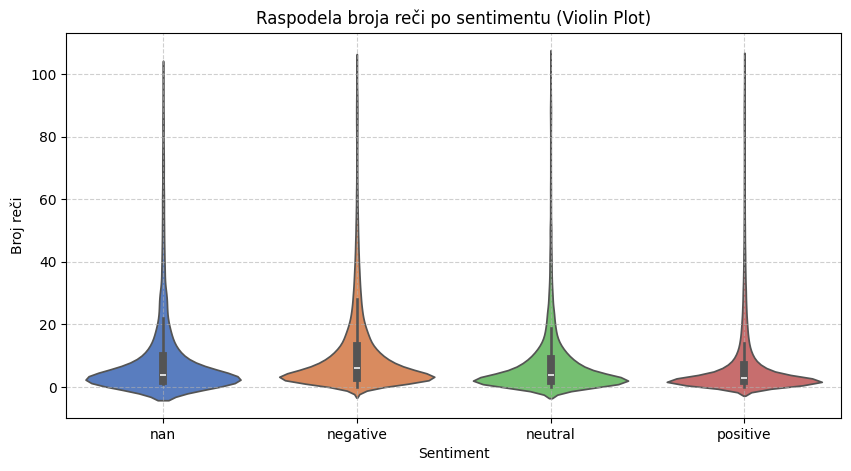

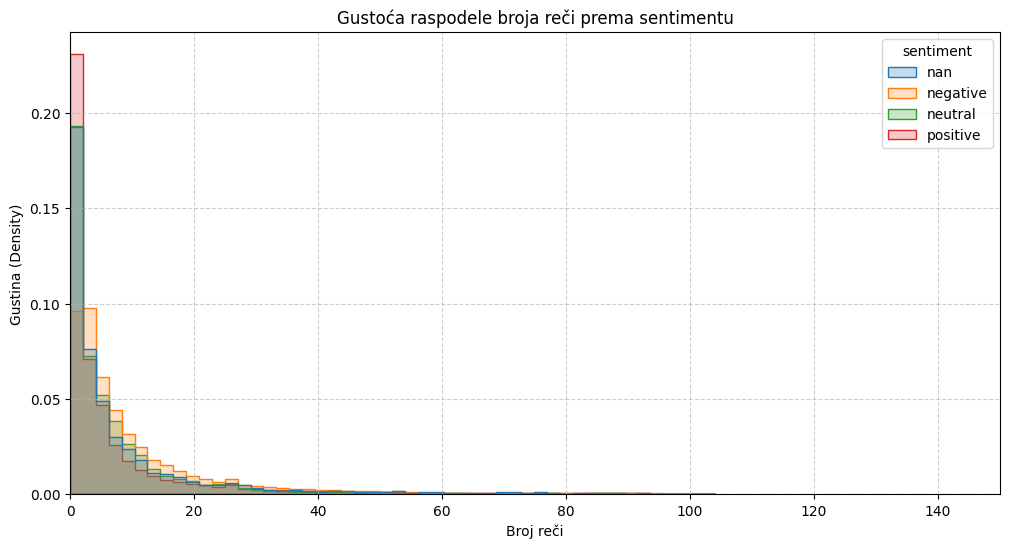

In [13]:
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Dodajemo novu kolonu: broj reči u recenziji (umesto samo karaktera)
df['word_count'] = df['review_text'].astype(str).str.split().apply(len)

# Prikaz osnovnih statistika za broj reči
print("Statistika broja reči po sentimentu:")
print(df.groupby('sentiment', observed=False)['word_count'].describe())

# 2. Vizualizacija 1: Violin plot za dužinu u rečima po sentimentu
plt.figure(figsize=(10, 5))
sns.violinplot(data=df, x='sentiment', y='word_count', palette='muted')
plt.title("Raspodela broja reči po sentimentu (Violin Plot)")
plt.xlabel("Sentiment")
plt.ylabel("Broj reči")
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

# 3. Vizualizacija 2: Histogram / KDE plot (preklopljene raspodele za dublji uvid)
plt.figure(figsize=(12, 6))
sns.histplot(data=df, x='word_count', hue='sentiment', element='step', common_norm=False, stat='density', bins=50)
plt.title("Gustoća raspodele broja reči prema sentimentu")
plt.xlabel("Broj reči")
plt.ylabel("Gustina (Density)")
plt.xlim(0, 150) # Ograničavamo prikaz na 150 reči da grafik bude pregledniji (uklanjamo "romane" sa 500+ reči za vizuelni fokus)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

## Training and comparing multiple machine learning models

In this lesson, we will train and evaluate several different machine learning models in order to find the best one for our classification task.

We will go through the following steps:
- Split the dataset into training and test sets.
- Prepare the data by:
  - transforming the review title and review text columns using **TF-IDF**,
  - scaling the review length column using **MinMaxScaler**.
- Use a **ColumnTransformer** to combine all features into a single input matrix.
- Define and train **five different classification algorithms**.
- Wrap all components into a unified **Pipeline** for each model.
- Evaluate model performance using **classification reports**.

By the end of this lesson, you will be able to compare the strengths and weaknesses of different algorithms and select the most suitable one for your project.

In [14]:
from sklearn.model_selection import train_test_split

from sklearn.preprocessing import MinMaxScaler
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import LinearSVC
from sklearn.metrics import classification_report

#--------------------------------------
# Proveri da li kolona postoji, pa je dodaj ako nedostaje
if 'review_length' not in df.columns:
    df['review_length'] = df['review_text'].astype(str).str.len()
#--------------------------------------

# Features and label
X = df[["review_title", "review_text", "review_length"]]
y = df["sentiment"]

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)


# Preprocessor: TF-IDF for text, MinMaxScaler for numeric feature
preprocessor = ColumnTransformer(
    transformers=[
        ("title", TfidfVectorizer(), "review_title"),
        ("text", TfidfVectorizer(), "review_text"),
        ("length", MinMaxScaler(), ["review_length"])
    ]
)


# List of classifiers
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Naive Bayes": MultinomialNB(),
    "Decision Tree": DecisionTreeClassifier(),
    "Random Forest": RandomForestClassifier(),
    "Support Vector Machine": LinearSVC()
}

# Train and evaluate
for name, model in models.items():
    print(f"\n {name}")
    pipeline = Pipeline([
        ("preprocessing", preprocessor),
        ("classifier", model)
    ])

    pipeline.fit(X_train, y_train)
    y_pred = pipeline.predict(X_test)
    print(classification_report(y_test, y_pred))




 Logistic Regression


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


              precision    recall  f1-score   support

         nan       0.00      0.00      0.00       999
    negative       0.85      0.93      0.89      8933
     neutral       0.71      0.52      0.60      2735
    positive       0.93      0.97      0.95     21524

    accuracy                           0.90     34191
   macro avg       0.62      0.60      0.61     34191
weighted avg       0.87      0.90      0.88     34191


 Naive Bayes


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


              precision    recall  f1-score   support

         nan       0.00      0.00      0.00       999
    negative       0.83      0.89      0.86      8933
     neutral       0.81      0.27      0.41      2735
    positive       0.89      0.98      0.93     21524

    accuracy                           0.87     34191
   macro avg       0.63      0.54      0.55     34191
weighted avg       0.84      0.87      0.84     34191


 Decision Tree
              precision    recall  f1-score   support

         nan       0.03      0.02      0.02       999
    negative       0.85      0.89      0.87      8933
     neutral       0.59      0.57      0.58      2735
    positive       0.93      0.94      0.94     21524

    accuracy                           0.87     34191
   macro avg       0.60      0.60      0.60     34191
weighted avg       0.86      0.87      0.86     34191


 Random Forest
              precision    recall  f1-score   support

         nan       0.03      0.00      0.01